# 02 Estimate: baselines and models on the validation folds, choice of the main model

**Purpose.** Answer the second half of the project question: how well can the credit spread over SOFR of a newly
originated private credit loan be predicted at the start of its quarter, and with which model? This notebook runs the
horse race of deck 16 / notebook 209: the two committed baselines and every course model on the **same four
time-ordered validation folds** with the **same metric**, tunes each model on these folds, and records the chosen main
model before any test prediction is made.

**Input.** `data/processed/loans.csv` (built by `01_preprocess.ipynb`), loaded with `code/modelling_helpers.py`.
Only rows with `split == "train"` (2023Q2 to 2025Q2) are used until the last steps.

**Output.**
- `data/processed/predictions_validation.csv`: one row per model and validation loan (`model, fold, loan_id,
  quarter, family, y_true, y_pred, abs_error_bps`). Notebook 03 uses the same columns for the test predictions.
- Summary of approach and findings: `docs/model_report.md` (counterpart of `docs/data_report.md`).
- `output/tables/horse_race_validation.csv`, `output/tables/tuning_default_vs_tuned.csv`,
  `output/figures/horse_race_validation.png`.
- Later steps (next work session): `output/tables/model_choice.csv`, the test and robustness predictions.

**What is fixed** (CLAUDE.md, `docs/lecturer_feedback_and_commitments.md`, `docs/for_modelling.md`, D41, D45):
- Target `spread_pp` (percentage points); errors reported in basis points (x 100).
- Validation: expanding window by quarter, one-quarter gap (to predict quarter t, train on loans up to t-2 that were
  filed before the start of t): validation quarters 2024Q3, 2024Q4, 2025Q1, 2025Q2.
- Metrics: MAE in bps (main), share of loans within plus or minus 50 bps. The model is chosen on the MAE pooled over
  all validation loans; the per-fold MAEs show the spread (deck 16, rule 4: a simpler model is preferred when the gap
  is within the spread across the folds).
- Features: `mh.NUM` + `mh.CAT`; never interest rate, fair value, cost, PIK or floor. All learned preprocessing inside
  a scikit-learn pipeline fitted on the training fold only.
- The test quarters (2025Q3 to 2026Q2) are not used for any choice; this notebook computes no test error (D45).

**Steps.** 0 setup, 1 data and folds, 2 baselines, 3 linear models, 4 trees, 5 neural network, 6 horse race (6b patterns explained, 6c how good a
prediction from these features can be, 6d second round with the deviation from the market median as
target, 6e both rounds and the files for notebook 03).
(Next session: 7 optional features, 8 model choice, 9 test predictions, 10 robustness predictions.)
Every step ends with a check. Decisions are logged in `docs/decisions.md`.

## Step 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
# A manager family or sector first seen in a validation quarter is mapped to the pooled "infrequent" group by the
# encoder (see mh.make_preprocessor); scikit-learn warns about it every time. Counted in step 1 instead.
warnings.filterwarnings("ignore", message="Found unknown categories")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import modelling_helpers as mh  # noqa: E402

PROC = ROOT / "data" / "processed"
FIG = ROOT / "output" / "figures"
TAB = ROOT / "output" / "tables"
SEED = 42                       # used for every model with randomness
np.random.seed(SEED)
print("project folder:", ROOT.name, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

project folder: DSF_Project | pandas 3.1.1 | scikit-learn 1.9.1


## Step 1. Data and validation folds (training rows only)

**What.** We load the working dataset and keep only the training rows. `mh.time_cv_splits` builds four
expanding-window folds: each validation quarter is predicted by data that ends two quarters earlier and was filed
before the validation quarter starts.

**Why.** The test quarters stay untouched until the end (deck 08, deck 16 rule 1). The folds imitate how the model
would be used: at the start of a quarter, only filings that are already public can be used.

**Check.** Only training rows; fold sizes; for every fold the last training quarter is at most t-2 and every training
loan was filed before the validation quarter starts; no missing values in the features.

In [2]:
df = mh.load_data(PROC / "loans.csv")
train = df[df["split"] == "train"].reset_index(drop=True)
FEATURES = mh.NUM + mh.CAT
folds = list(mh.time_cv_splits(train))

rows = []
for k, (tr_idx, va_idx) in enumerate(folds):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    t = va["quarter"].iloc[0]
    assert va["quarter"].nunique() == 1
    assert tr["quarter"].max() <= t - 2                       # one-quarter gap
    assert (tr["filed_date"] < t.start_time).all()            # training loans public at the cutoff
    rows.append({"fold": k, "validation_quarter": str(t), "n_train": len(tr),
                 "train_quarters": f"{tr['quarter'].min()} to {tr['quarter'].max()}", "n_validation": len(va)})
fold_table = pd.DataFrame(rows)
print(fold_table.to_string(index=False))

# Check
assert (train["split"] == "train").all() and train["quarter"].max() == pd.Period("2025Q2")
assert train[FEATURES].notna().all().all()
unseen = sum(int((~train.iloc[va]["family"].isin(train.iloc[tr]["family"])).sum()) for tr, va in folds)
print(f"validation loans whose manager family is not in the training part of their fold: {unseen} "
      "(encoded as the pooled infrequent group)")
print(f"training rows: {len(train)} (test rows not used: {(df['split'] == 'test').sum()}); "
      f"validation loans over the 4 folds: {fold_table['n_validation'].sum()}")

 fold validation_quarter  n_train   train_quarters  n_validation
    0             2024Q3      295 2023Q2 to 2024Q1           180
    1             2024Q4      447 2023Q2 to 2024Q2           205
    2             2025Q1      627 2023Q2 to 2024Q3           151
    3             2025Q2      830 2023Q2 to 2024Q4           139
validation loans whose manager family is not in the training part of their fold: 61 (encoded as the pooled infrequent group)
training rows: 1122 (test rows not used: 583); validation loans over the 4 folds: 675


## Step 2. Baselines

**What.** The two baselines committed in our project description, both with the t-2 rule (`docs/for_modelling.md`):
1. **Market median (t-2):** the median spread of all new BDC loans first seen in quarter t-2 and filed before the
   start of t (the column `mkt_spread_t2_all`, built in notebook 01). One number per quarter for every loan.
2. **Sector x size median:** the median spread in the loan's sector and size tercile over the quarters t-5 to t-2
   (fallback: the sector median, then baseline 1 when a cell has fewer than 5 loans).

As a **reference only** (not a committed baseline) we add the mean spread of the training fold, the "mean" baseline
of deck 16. It shows how much is lost by ignoring that spreads fell over time.

**Why.** A model earns its place only if it beats the best simple rule on the same folds and metric (deck P1). A deal
team could compute baseline 1 from public filings in minutes.

**Check.** (a) Baseline 1 is constant within a quarter and equals the feature column; it is compared with the median
of the all-BDC loan file for the same quarter (a plausibility check: notebook 01 computes it on a slightly wider pool
of new loans). (b) One baseline-2 prediction is recomputed step by step with separate code.

In [3]:
def fold_frame(model_name, k, rows, y_pred):
    # Predictions of one model on one validation fold, in the common format (see mh.error_frame)
    return mh.error_frame(rows, y_pred).assign(model=model_name, fold=k)


val_preds = []          # every model and baseline appends its validation predictions here
for k, (tr_idx, va_idx) in enumerate(folds):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    val_preds.append(fold_frame("Baseline 1: market median t-2", k, va, mh.baseline_t2(va)))
    val_preds.append(fold_frame("Baseline 2: sector x size median", k, va, mh.baseline_sector_size(train, va)))
    val_preds.append(fold_frame("Reference: training mean", k, va, np.full(len(va), tr[mh.TARGET].mean())))
val = pd.concat(val_preds, ignore_index=True)


def race_table(val):
    # Pooled MAE over all validation loans (choice criterion, D45), the MAE of each fold, and the share within 50 bps
    pooled = val.groupby("model", sort=False).apply(mh.summarize_errors, include_groups=False)
    by_fold = val.groupby(["model", "fold"], sort=False)["abs_error_bps"].mean().unstack()
    by_fold.columns = [f"mae_fold{c}_{fold_table.loc[c, 'validation_quarter']}" for c in by_fold.columns]
    out = pooled.join(by_fold)
    out["fold_spread_bps"] = by_fold.max(axis=1) - by_fold.min(axis=1)
    return out.round({"mae_bps": 1, "share_within_50bps": 3, **{c: 1 for c in by_fold.columns}, "fold_spread_bps": 1})


print(race_table(val).to_string())

                                      n  mae_bps  share_within_50bps  mae_fold0_2024Q3  mae_fold1_2024Q4  mae_fold2_2025Q1  mae_fold3_2025Q2  fold_spread_bps
model                                                                                                                                                        
Baseline 1: market median t-2     675.0     78.6               0.584              77.9              76.3              85.4              75.4             10.0
Baseline 2: sector x size median  675.0     98.3               0.385             115.8              99.3              95.5              77.2             38.6
Reference: training mean          675.0     96.0               0.409             112.0              93.1              96.4              79.2             32.7


In [4]:
# Check (a): baseline 1 is the column mkt_spread_t2_all, one value per quarter, known at the cutoff
per_q = train.groupby("quarter")["mkt_spread_t2_all"].nunique()
assert (per_q == 1).all()
all_bdc = mh.load_data(PROC / "loans_all_bdc.csv")
check = []
for t in fold_table["validation_quarter"].map(pd.Period):
    ref = all_bdc[(all_bdc["quarter"] == t - 2) & (all_bdc["filed_date"] < t.start_time)]
    check.append({"quarter": str(t), "baseline_1": train.loc[train["quarter"] == t, "mkt_spread_t2_all"].iloc[0],
                  "median_all_bdc_file_t-2": ref["spread_pp"].median(), "n_loans_t-2": len(ref)})
print(pd.DataFrame(check).to_string(index=False))

# Check (b): recompute baseline 2 for every validation loan with separate code (a loop over loans), including the
# fallbacks, and count which rule produced each prediction
by_hand, source = [], []
for k, (tr_idx, va_idx) in enumerate(folds):
    va = train.iloc[va_idx]
    t = va["quarter"].iloc[0]
    window = train[(train["quarter"] >= t - 5) & (train["quarter"] <= t - 2) & (train["filed_date"] < t.start_time)]
    cut1, cut2 = np.quantile(window["log_principal"], [1 / 3, 2 / 3])
    size = lambda x: 0 if x < cut1 else (1 if x < cut2 else 2)
    window_size = window["log_principal"].map(size)
    for _, loan in va.iterrows():
        same_sector = window[window["sector"] == loan["sector"]]
        cell = same_sector[window_size[same_sector.index] == size(loan["log_principal"])]
        if len(cell) >= 5:
            by_hand.append(cell["spread_pp"].median()); source.append("sector x size cell")
        elif len(same_sector) >= 5:
            by_hand.append(same_sector["spread_pp"].median()); source.append("fallback: sector median")
        else:
            by_hand.append(loan["mkt_spread_t2_all"]); source.append("fallback: baseline 1")
helper = val.loc[val["model"] == "Baseline 2: sector x size median", "y_pred"].to_numpy()
assert np.allclose(np.array(by_hand), helper)
print("baseline 2 recomputed by hand for all", len(helper), "validation loans: identical to the helper")
print(pd.Series(source).value_counts().to_string())

quarter  baseline_1  median_all_bdc_file_t-2  n_loans_t-2
 2024Q3        5.00                     5.00          547
 2024Q4        5.00                     5.00          671
 2025Q1        5.00                     5.00          650
 2025Q2        4.75                     4.75          728


baseline 2 recomputed by hand for all 675 validation loans: identical to the helper
sector x size cell         634
fallback: sector median     33
fallback: baseline 1         8


## How every model is tuned (applies to steps 3 to 5)

**What.** Each model class gets a small grid of hyperparameters. Every setting is fitted on the training part of each
of the four folds and scored on the pooled validation MAE; the best setting is the **tuned** version. The
scikit-learn **default** setting is scored the same way, for the table "default against tuned" that deck 16 asks for.
Every model sits in a pipeline behind `mh.make_preprocessor()` (median imputation, z-scores, one-hot encoding with
rare categories pooled), so all learned preprocessing is fitted on the training fold only.

**Why.** Deck 16: tune every horse the same way, inside the time-ordered cross-validation, with modest searches.
The tuned score is slightly optimistic (it is the best of several tries on the same folds); this is why the test
quarters are needed at the end. The grids are kept small on purpose (D45, E4) and each value is explained.

In [5]:
import itertools
import time
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor


def run_folds(name, make_model, features=FEATURES):
    # Fit a fresh model on the training part of every fold and predict the validation quarter
    out = []
    for k, (tr_idx, va_idx) in enumerate(folds):
        tr, va = train.iloc[tr_idx], train.iloc[va_idx]
        model = make_model()
        model.fit(tr[features], tr[mh.TARGET])
        out.append(fold_frame(name, k, va, model.predict(va[features])))
    return pd.concat(out, ignore_index=True)


class ResidualOnMarket:
    # Residual target (step 6d, D47): the model learns spread minus the market median of quarter t-2
    # (mkt_spread_t2_all, a feature known at the cutoff); the prediction adds the market median back.
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, y - X["mkt_spread_t2_all"])
        return self

    def predict(self, X):
        return self.model.predict(X) + X["mkt_spread_t2_all"].to_numpy()


def tune(name, estimator, grid, default_params=None, residual=False):
    # Score the default and every grid setting on the same folds; return the tuned predictions and a summary
    pipe = lambda params: make_pipeline(mh.make_preprocessor(), estimator(**params))
    make = lambda params: (lambda: ResidualOnMarket(pipe(params)) if residual else pipe(params))
    start = time.time()
    default = run_folds(name, make(default_params or {}))
    keys = list(grid)
    # The default setting competes with the grid, so tuning can never end worse than the default (D47)
    defaults_of_keys = {k: estimator(**(default_params or {})).get_params()[k] for k in keys}
    results = [(default["abs_error_bps"].mean(), defaults_of_keys, default)]
    for values in itertools.product(*grid.values()):
        params = dict(zip(keys, values))
        frame = run_folds(name, make({**(default_params or {}), **params}))
        results.append((frame["abs_error_bps"].mean(), params, frame))
    results.sort(key=lambda r: r[0])
    best_mae, best_params, best_frame = results[0]
    grid_table = pd.DataFrame([{**p, "mae_bps": round(m, 1)} for m, p, _ in results])
    summary = {"model": name, "default_mae_bps": round(default["abs_error_bps"].mean(), 1),
               "tuned_mae_bps": round(best_mae, 1), "tuned_params": str(best_params),
               "n_settings": len(results), "seconds": round(time.time() - start, 1)}
    print(f"{name}: default {summary['default_mae_bps']} bps, tuned {summary['tuned_mae_bps']} bps with "
          f"{best_params} ({len(results)} settings x 4 folds, {summary['seconds']} s)")
    return best_frame, best_params, grid_table, summary


def at_edge(grid_values, best_value):
    # A best value at the edge of a 1-D grid means the grid should be extended (notebook 209, step 6)
    return best_value in (grid_values[0], grid_values[-1])


tuning = []          # one summary row per model: default against tuned

## Step 3. Linear models: linear regression, ridge, lasso

**What.** Linear regression (no hyperparameter); ridge and lasso with the penalty `alpha` on a log grid. The default
`alpha` is 1.0 in scikit-learn for both.

**Why.** The simplest models of the course (decks 02 and 05). With about 40 columns after one-hot encoding and 300 to
830 training loans per fold, a penalty may help the small manager families and sectors. Lasso also shows which
columns the model can do without.

**Check.** The best `alpha` lies inside the grid; number of non-zero lasso coefficients; predictions in a plausible
range (no spread below 1 or above 15 pp, the range of the sample).

In [6]:
ols = run_folds("Linear regression", lambda: make_pipeline(mh.make_preprocessor(), LinearRegression()))
ols_mae = ols["abs_error_bps"].mean()
tuning.append({"model": "Linear regression", "default_mae_bps": round(ols_mae, 1), "tuned_mae_bps": round(ols_mae, 1),
               "tuned_params": "none", "n_settings": 1, "seconds": np.nan})
print(f"Linear regression: {ols_mae:.1f} bps")

RIDGE_ALPHAS = [0.1, 1, 3, 10, 30, 100, 300, 1000]
LASSO_ALPHAS = [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1]
ridge, ridge_p, ridge_grid, s = tune("Ridge", Ridge, {"alpha": RIDGE_ALPHAS}); tuning.append(s)
lasso, lasso_p, lasso_grid, s = tune("Lasso", Lasso, {"alpha": LASSO_ALPHAS}, {"max_iter": 50000}); tuning.append(s)
print(ridge_grid.T.to_string(header=False)); print(lasso_grid.T.to_string(header=False))

# Check
for label, grid_vals, best in [("ridge", RIDGE_ALPHAS, ridge_p["alpha"]), ("lasso", LASSO_ALPHAS, lasso_p["alpha"])]:
    print(f"{label}: best alpha {best}", "AT THE EDGE of the grid" if at_edge(grid_vals, best) else "inside the grid")
fit = make_pipeline(mh.make_preprocessor(), Lasso(alpha=lasso_p["alpha"], max_iter=50000))
fit.fit(train.iloc[folds[-1][0]][FEATURES], train.iloc[folds[-1][0]][mh.TARGET])
names_out = fit[0].get_feature_names_out()
coef = pd.Series(fit[-1].coef_, index=names_out)
print(f"lasso (last fold): {(coef != 0).sum()} of {len(coef)} coefficients not zero; set to zero:",
      list(coef[coef == 0].index))
for frame in [ols, ridge, lasso]:
    assert frame["y_pred"].between(1, 15).all(), frame["model"].iloc[0]

Linear regression: 74.9 bps


Ridge: default 72.3 bps, tuned 72.1 bps with {'alpha': 3} (9 settings x 4 folds, 0.6 s)


Lasso: default 96.0 bps, tuned 68.5 bps with {'alpha': 0.01} (8 settings x 4 folds, 0.5 s)
alpha     3.0   1.0   1.0  10.0  30.0   0.1  100.0  300.0  1000.0
mae_bps  72.1  72.3  72.3  72.8  73.1  74.3   74.8   80.3    87.4
alpha     0.01   0.03   0.003   0.001   0.1   0.0003   1.0   1.0
mae_bps  68.50  69.20  69.300  72.500  73.1  74.0000  96.0  96.0
ridge: best alpha 3 inside the grid
lasso: best alpha 0.01 inside the grid
lasso (last fold): 15 of 43 coefficients not zero; set to zero: ['cat__sector_Consumer Discretionary', 'cat__sector_Consumer Staples', 'cat__sector_Energy', 'cat__sector_Financials', 'cat__sector_Health Care', 'cat__sector_Materials', 'cat__sector_Real Estate', 'cat__sector_infrequent_sklearn', 'cat__lien_first_lien_last_out', 'cat__lien_infrequent_sklearn', 'cat__family_Bain Capital', 'cat__family_BlackRock', 'cat__family_Brightwood Capital Corp I', 'cat__family_Comvest', 'cat__family_Crescent', 'cat__family_Diameter Credit Co', 'cat__family_Jefferies', 'cat__famil

## Step 4. Trees: one tree, random forest, boosting

**What.** One regression tree (grid: depth and minimum leaf size), a random forest (grid: share of features tried at
each split and minimum leaf size; 300 trees), gradient boosting (grid: learning rate, number of trees, depth of each
tree; 80% of the loans per tree). Fixed seed for all.

**Why.** Trees find interactions on their own (e.g. a sector premium that differs by size) and need no scaling
(deck 17). The forest needs `max_features` below 1: the scikit-learn default for regression uses all features, which
is plain bagging, not a random forest (deck 17). Boosting needs more tuning than a forest: learning rate, number of
trees and depth 2 to 3 (deck 17, notebook 210). The grids follow notebook 210 and stay small.

**Check.** Running time; tuned settings inside the grids; predictions in the plausible range.

In [7]:
tree, tree_p, tree_grid, s = tune("Tree", DecisionTreeRegressor,
                                  {"max_depth": [2, 3, 4, 6, 8], "min_samples_leaf": [5, 20]},
                                  {"random_state": SEED}); tuning.append(s)
forest, forest_p, forest_grid, s = tune("Random forest", RandomForestRegressor,
                                        {"max_features": ["sqrt", 0.33, 0.5], "min_samples_leaf": [1, 5, 10]},
                                        {"n_estimators": 300, "random_state": SEED, "n_jobs": -1}); tuning.append(s)
boost, boost_p, boost_grid, s = tune("Boosting", GradientBoostingRegressor,
                                     {"learning_rate": [0.03, 0.1], "n_estimators": [100, 300], "max_depth": [2, 3]},
                                     {"subsample": 0.8, "random_state": SEED}); tuning.append(s)
for g in [tree_grid, forest_grid, boost_grid]:
    print(g.head(4).to_string(index=False))

# Check
for frame in [tree, forest, boost]:
    assert frame["y_pred"].between(1, 15).all(), frame["model"].iloc[0]
print("tree depth", tree_p["max_depth"], "| forest", forest_p, "| boosting", boost_p)

Tree: default 108.5 bps, tuned 89.0 bps with {'max_depth': 3, 'min_samples_leaf': 5} (11 settings x 4 folds, 0.7 s)


Random forest: default 87.9 bps, tuned 85.4 bps with {'max_features': 0.5, 'min_samples_leaf': 1} (10 settings x 4 folds, 15.1 s)


Boosting: default 90.4 bps, tuned 86.7 bps with {'learning_rate': 0.1, 'n_estimators': 100, 'max_depth': 2} (9 settings x 4 folds, 4.4 s)
 max_depth  min_samples_leaf  mae_bps
       3.0                 5     89.0
       4.0                20     89.7
       2.0                 5     91.4
       2.0                20     91.4
max_features  min_samples_leaf  mae_bps
         0.5                 1     85.4
        0.33                 1     85.7
        0.33                10     86.1
         0.5                10     86.4
 learning_rate  n_estimators  max_depth  mae_bps
          0.10           100          2     86.7
          0.03           100          3     88.7
          0.03           100          2     89.4
          0.10           300          2     89.8
tree depth 3 | forest {'max_features': 0.5, 'min_samples_leaf': 1} | boosting {'learning_rate': 0.1, 'n_estimators': 100, 'max_depth': 2}


## Step 5. A small neural network

**What.** A feedforward network (`MLPRegressor`, deck 14/15, notebook 207) with one or two small hidden layers and
early stopping; grid: layer sizes and the L2 penalty `alpha`. The scikit-learn default is one hidden layer of 100
units without early stopping.

**Why.** Deck 16: for neural networks, standard settings and early stopping are enough. Early stopping holds back 10%
of the training fold (never the validation quarter) to stop training when the error there stops falling.

**Check.** Converged fits; predictions in the plausible range.

In [8]:
net, net_p, net_grid, s = tune("Neural network", MLPRegressor,
                               {"hidden_layer_sizes": [(16,), (32,), (32, 16)], "alpha": [0.0001, 0.01]},
                               {"early_stopping": True, "max_iter": 2000, "random_state": SEED}); tuning.append(s)
print(net_grid.to_string(index=False))

# Check
print(f"predictions from {net['y_pred'].min():.2f} to {net['y_pred'].max():.2f} pp")
assert net["y_pred"].between(1, 15).all()

Neural network: default 149.9 bps, tuned 126.6 bps with {'hidden_layer_sizes': (32,), 'alpha': 0.0001} (7 settings x 4 folds, 11.3 s)
hidden_layer_sizes  alpha  mae_bps
             (32,) 0.0001    126.6
             (32,) 0.0100    127.8
          (32, 16) 0.0001    135.0
          (32, 16) 0.0100    135.7
            (100,) 0.0001    149.9
             (16,) 0.0100    155.4
             (16,) 0.0001    157.7
predictions from 1.40 to 8.44 pp


## Step 6. The horse race on the validation folds

**What.** All baselines and tuned models in one table and one figure (as in notebooks 209 and 210): pooled MAE (the
choice criterion), MAE per fold, spread across the folds, share within 50 bps, and in how many of the four folds the
model beats baseline 1. A second table compares default and tuned settings (deck 16, for the backup slides).

**Why.** The same folds and the same metric for every candidate make the comparison fair. Deck 16, rule 4: the model
with the lowest validation error, or a simpler one if the gap is within the spread across the folds. Beating the
baseline in every fold, not only on average, is a sanity check of deck P1.

**Check.** Every candidate predicts every validation loan exactly once. (The files are written in 6e, after the
second round.)

In [9]:
val = pd.concat([val, ols, ridge, lasso, tree, forest, boost, net], ignore_index=True)
assert val.groupby("model").size().eq(fold_table["n_validation"].sum()).all()   # every model predicts every loan once

def full_race(val):
    # Race table plus: in how many folds a model beats baseline 1, and its mean gain over baseline 1 per fold
    race = race_table(val)
    b1 = val[val["model"] == "Baseline 1: market median t-2"].groupby("fold")["abs_error_bps"].mean()
    by_fold = val.groupby(["model", "fold"])["abs_error_bps"].mean().unstack()
    race["folds_beating_baseline_1"] = (by_fold.lt(b1, axis=1)).sum(axis=1)
    race["gain_vs_baseline_1_bps"] = (b1.mean() - by_fold.mean(axis=1)).round(1)   # mean of the four fold MAEs
    return race.sort_values("mae_bps"), by_fold


race, by_fold = full_race(val)
print(race.to_string())

                                      n  mae_bps  share_within_50bps  mae_fold0_2024Q3  mae_fold1_2024Q4  mae_fold2_2025Q1  mae_fold3_2025Q2  fold_spread_bps  folds_beating_baseline_1  gain_vs_baseline_1_bps
model                                                                                                                                                                                                          
Lasso                             675.0     68.5               0.487              68.9              70.0              65.1              69.3              4.9                         4                    10.4
Ridge                             675.0     72.1               0.431              67.4              83.9              67.7              65.7             18.2                         3                     7.5
Linear regression                 675.0     74.9               0.418              69.6              91.6              67.5              65.0             26.6           

### 6b. Two patterns in the race, explained

**(1) Why the tree models lose to baseline 1.** Spreads fell over the sample period. In every fold the market level of
the validation quarter (`mkt_spread_t2_all`, `sofr_prev`) lies **outside** the range seen in training. A tree can only
predict averages of training loans, so it cannot go below the lowest level it has seen; a linear model extends the
line. The table shows the range of each market feature in training and in validation.

**(2) Why baseline 1 has the highest share within 50 bps but not the lowest MAE.** About 97% of spreads are quoted on a
25 bps grid and many equal the market median exactly, so a constant median often hits a loan exactly (error 0). The
models predict values between grid points: fewer exact hits, but fewer large misses. Both views go to notebook 03.

In [10]:
rows = []
for k, (tr_idx, va_idx) in enumerate(folds):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    for c in ["mkt_spread_t2_all", "sofr_prev", "baa_spread_prev"]:
        rows.append({"fold": k, "feature": c, "train_min": tr[c].min(), "train_max": tr[c].max(),
                     "validation_value": va[c].iloc[0],
                     "outside_training_range": not tr[c].min() <= va[c].iloc[0] <= tr[c].max()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

print(f"share of training spreads on a 25 bps grid: {np.isclose((train[mh.TARGET] * 4) % 1, 0).mean():.3f}")
pattern = val.groupby("model")["abs_error_bps"].agg(
    exact_hit=lambda e: (e < 1).mean(), within_50=lambda e: (e <= 50).mean(),
    median_error=lambda e: e.median(), miss_over_150=lambda e: (e > 150).mean())
print(pattern.loc[race.index].round(3).to_string())

 fold           feature  train_min  train_max  validation_value  outside_training_range
    0 mkt_spread_t2_all       5.50       6.75              5.00                    True
    0         sofr_prev       4.87       5.38              5.33                   False
    0   baa_spread_prev       1.61       2.11              1.55                    True
    1 mkt_spread_t2_all       5.50       6.75              5.00                    True
    1         sofr_prev       4.87       5.38              4.96                   False
    1   baa_spread_prev       1.50       2.11              1.63                   False
    2 mkt_spread_t2_all       5.00       6.75              5.00                   False
    2         sofr_prev       4.87       5.38              4.49                    True
    2   baa_spread_prev       1.50       2.11              1.42                    True
    3 mkt_spread_t2_all       5.00       6.75              4.75                    True
    3         sofr_prev       4.

### 6c. How good can a prediction from these features be? (diagnostic, validation folds only)

**What.** Four numbers per fold for the best model so far (lasso): its error on its own training data, its error on
the validation quarter, its mean error (positive = it predicts too low), and two reference points that use the
validation outcomes and are therefore **not** usable predictions, only yardsticks:
(a) the error of the true median of the validation quarter (perfect knowledge of the market level, nothing else);
(b) the error of a lasso fitted on the validation quarter itself (the best a linear model with these features can
explain in-sample; non-linear models can go lower, see 6d).
Then the errors of the lasso by size of the true spread.

**Why.** To tell apart a model that is badly built (overfitting, a bug) from a task with limited information. The
filings contain no borrower credit data (leverage, earnings, sponsor), which drive much of a loan's spread.

**Check.** Training and validation error are close (no overfitting); no feature is a never-feature.

In [11]:
dd = pd.read_csv(PROC / "data_dictionary.csv")
assert not set(FEATURES) & set(dd.loc[dd["role"] == "never_feature", "column"])
make_lasso = lambda: make_pipeline(mh.make_preprocessor(), Lasso(alpha=lasso_p["alpha"], max_iter=50000))
rows = []
for k, (tr_idx, va_idx) in enumerate(folds):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    m = make_lasso().fit(tr[FEATURES], tr[mh.TARGET])
    in_sample = make_lasso().fit(va[FEATURES], va[mh.TARGET])
    err = va[mh.TARGET] - m.predict(va[FEATURES])
    rows.append({"fold": k, "validation_quarter": str(va["quarter"].iloc[0]),
                 "lasso_training_mae": (tr[mh.TARGET] - m.predict(tr[FEATURES])).abs().mean() * 100,
                 "lasso_validation_mae": err.abs().mean() * 100, "lasso_mean_error": err.mean() * 100,
                 "yardstick_true_quarter_median": (va[mh.TARGET] - va[mh.TARGET].median()).abs().mean() * 100,
                 "yardstick_lasso_fitted_on_quarter": (va[mh.TARGET] - in_sample.predict(va[FEATURES])).abs().mean() * 100})
ceiling = pd.DataFrame(rows).round(1)
print(ceiling.to_string(index=False))
assert (ceiling["lasso_validation_mae"] - ceiling["lasso_training_mae"]).abs().max() < 10   # no overfitting

lasso_val = val[val["model"] == "Lasso"].copy()
lasso_val["true_spread"] = pd.cut(lasso_val["y_true"], [0, 4, 5, 6, 7, 20],
                                  labels=["up to 4 pp", "4 to 5", "5 to 6", "6 to 7", "above 7"])
by_band = lasso_val.groupby("true_spread", observed=True).agg(
    n=("y_true", "size"), mae_bps=("abs_error_bps", "mean"), mean_prediction_pp=("y_pred", "mean"))
print(by_band.round(2).to_string())
big = lasso_val["abs_error_bps"] > 150
print(f"loans with an error above 150 bps: {big.mean():.1%} of loans, "
      f"{lasso_val.loc[big, 'abs_error_bps'].sum() / lasso_val['abs_error_bps'].sum():.1%} of the total error")
ceiling.to_csv(TAB / "validation_error_yardsticks.csv", index=False)

 fold validation_quarter  lasso_training_mae  lasso_validation_mae  lasso_mean_error  yardstick_true_quarter_median  yardstick_lasso_fitted_on_quarter
    0             2024Q3                68.5                  68.9             -23.2                           77.9                               55.1
    1             2024Q4                68.0                  70.0             -41.8                           76.3                               55.7
    2             2025Q1                65.6                  65.1               0.4                           82.5                               58.7
    3             2025Q2                63.4                  69.3              -6.4                           74.5                               54.5
               n  mae_bps  mean_prediction_pp
true_spread                                  
up to 4 pp   153   113.10                4.29
4 to 5       311    45.56                4.96
5 to 6       167    48.75                5.36
6 to 7        2

### 6d. Second round: every model predicts the deviation from the market median (residual target, D47)

**What.** The same models, grids, folds and metric, with one change: each model is trained on the **deviation of a
loan's spread from the market median** of quarter t-2 (`spread_pp - mkt_spread_t2_all`), and its prediction is that
deviation plus the market median. The target we predict and score is unchanged (the spread); baseline 1 is the special
case "predicted deviation = 0". All features stay the same.

**Why.** Step 6b showed that the market level of every validation quarter lies outside the training range, so trees
and the neural network cannot follow the falling market. The deviation from the market median ("this loan is priced
50 bps above the market because it is small and second lien") is in a similar range in every year, so no model has to
extrapolate. Step 6c showed that most of the error comes from differences between loans within a quarter, which is
exactly what the deviation describes. This round tests that diagnosis; it is chosen or rejected on the validation
folds only.

**Check.** Same folds, every loan predicted once; predictions in the plausible range; the deviation of the training
loans has a similar spread in every year (printed).

In [12]:
dev = train[mh.TARGET] - train["mkt_spread_t2_all"]
print("deviation from the market median, training loans, by year (pp):")
print(dev.groupby(train["quarter_str"].str[:4]).describe()[["count", "mean", "25%", "50%", "75%"]].round(2).to_string())

r_ols = run_folds("Linear regression (residual)",
                  lambda: ResidualOnMarket(make_pipeline(mh.make_preprocessor(), LinearRegression())))
r_mae = r_ols["abs_error_bps"].mean()
tuning.append({"model": "Linear regression (residual)", "default_mae_bps": round(r_mae, 1),
               "tuned_mae_bps": round(r_mae, 1), "tuned_params": "none", "n_settings": 1, "seconds": np.nan})
print(f"Linear regression (residual): {r_mae:.1f} bps")
r_ridge, r_ridge_p, _, s = tune("Ridge (residual)", Ridge, {"alpha": RIDGE_ALPHAS}, residual=True); tuning.append(s)
r_lasso, r_lasso_p, _, s = tune("Lasso (residual)", Lasso, {"alpha": LASSO_ALPHAS}, {"max_iter": 50000},
                                residual=True); tuning.append(s)
r_tree, r_tree_p, _, s = tune("Tree (residual)", DecisionTreeRegressor,
                              {"max_depth": [2, 3, 4, 6, 8], "min_samples_leaf": [5, 20]},
                              {"random_state": SEED}, residual=True); tuning.append(s)
r_forest, r_forest_p, _, s = tune("Random forest (residual)", RandomForestRegressor,
                                  {"max_features": ["sqrt", 0.33, 0.5], "min_samples_leaf": [1, 5, 10]},
                                  {"n_estimators": 300, "random_state": SEED, "n_jobs": -1}, residual=True)
tuning.append(s)
r_boost, r_boost_p, _, s = tune("Boosting (residual)", GradientBoostingRegressor,
                                {"learning_rate": [0.03, 0.1], "n_estimators": [100, 300], "max_depth": [2, 3]},
                                {"subsample": 0.8, "random_state": SEED}, residual=True); tuning.append(s)
r_net, r_net_p, _, s = tune("Neural network (residual)", MLPRegressor,
                            {"hidden_layer_sizes": [(16,), (32,), (32, 16)], "alpha": [0.0001, 0.01]},
                            {"early_stopping": True, "max_iter": 2000, "random_state": SEED}, residual=True)
tuning.append(s)

# Check
residual_round = [r_ols, r_ridge, r_lasso, r_tree, r_forest, r_boost, r_net]
for frame in residual_round:
    assert frame["y_pred"].between(1, 15).all(), frame["model"].iloc[0]
for label, grid_vals, best in [("ridge", RIDGE_ALPHAS, r_ridge_p["alpha"]), ("lasso", LASSO_ALPHAS, r_lasso_p["alpha"])]:
    print(f"{label} (residual): best alpha {best}", "AT THE EDGE" if at_edge(grid_vals, best) else "inside the grid")

deviation from the market median, training loans, by year (pp):
             count  mean   25%   50%   75%
quarter_str                               
2023         179.0 -0.31 -0.75  0.00  0.25
2024         653.0 -0.41 -1.10 -0.25  0.25
2025         290.0 -0.17 -0.69  0.00  0.25
Linear regression (residual): 74.9 bps


Ridge (residual): default 72.0 bps, tuned 64.7 bps with {'alpha': 100} (9 settings x 4 folds, 0.7 s)


Lasso (residual): default 86.8 bps, tuned 66.4 bps with {'alpha': 0.03} (8 settings x 4 folds, 0.5 s)


Tree (residual): default 78.7 bps, tuned 68.6 bps with {'max_depth': 4, 'min_samples_leaf': 5} (11 settings x 4 folds, 0.7 s)


Random forest (residual): default 61.4 bps, tuned 59.3 bps with {'max_features': 0.33, 'min_samples_leaf': 1} (10 settings x 4 folds, 12.9 s)


Boosting (residual): default 58.3 bps, tuned 58.3 bps with {'learning_rate': 0.1, 'n_estimators': 100, 'max_depth': 3} (9 settings x 4 folds, 4.4 s)


Neural network (residual): default 60.8 bps, tuned 60.8 bps with {'hidden_layer_sizes': (100,), 'alpha': 0.0001} (7 settings x 4 folds, 4.3 s)
ridge (residual): best alpha 100 inside the grid
lasso (residual): best alpha 0.03 inside the grid


### 6e. Both rounds in one race; files for notebook 03

**What.** Baselines and both rounds of every model in one table and one figure, the table "default against tuned"
for every candidate, and the validation predictions of all candidates in the file shared with notebook 03.

**Check.** Every candidate predicts every validation loan exactly once; files written.

In [13]:
val = pd.concat([val] + residual_round, ignore_index=True)
assert val.groupby("model").size().eq(fold_table["n_validation"].sum()).all()
race, by_fold = full_race(val)
print(race.to_string())
race.to_csv(TAB / "horse_race_validation.csv")

pair = pd.DataFrame({"spread_target": race.loc[[m for m in race.index if m + " (residual)" in race.index], "mae_bps"]})
pair["residual_target"] = [race.loc[m + " (residual)", "mae_bps"] for m in pair.index]
pair["gain_bps"] = pair["spread_target"] - pair["residual_target"]
print(pair.sort_values("residual_target").to_string())

tuning_table = pd.DataFrame(tuning)
tuning_table["gain_bps"] = tuning_table["default_mae_bps"] - tuning_table["tuned_mae_bps"]
tuning_table = tuning_table.merge(race["fold_spread_bps"], left_on="model", right_index=True, how="left")
tuning_table["gain_larger_than_fold_spread"] = tuning_table["gain_bps"] > tuning_table["fold_spread_bps"]
print(tuning_table.to_string(index=False))
tuning_table.to_csv(TAB / "tuning_default_vs_tuned.csv", index=False)

                                      n  mae_bps  share_within_50bps  mae_fold0_2024Q3  mae_fold1_2024Q4  mae_fold2_2025Q1  mae_fold3_2025Q2  fold_spread_bps  folds_beating_baseline_1  gain_vs_baseline_1_bps
model                                                                                                                                                                                                          
Boosting (residual)               675.0     58.3               0.576              55.1              57.3              60.4              61.5              6.4                         4                    20.2
Random forest (residual)          675.0     59.3               0.573              57.9              55.9              62.6              62.7              6.8                         4                    19.0
Neural network (residual)         675.0     60.8               0.559              62.3              55.7              63.6              63.5              7.9           

                   spread_target  residual_target  gain_bps
model                                                      
Boosting                    86.7             58.3      28.4
Random forest               85.4             59.3      26.1
Neural network             126.6             60.8      65.8
Ridge                       72.1             64.7       7.4
Lasso                       68.5             66.4       2.1
Tree                        89.0             68.6      20.4
Linear regression           74.9             74.9       0.0


                       model  default_mae_bps  tuned_mae_bps                                                tuned_params  n_settings  seconds  gain_bps  fold_spread_bps  gain_larger_than_fold_spread
           Linear regression             74.9           74.9                                                        none           1      NaN       0.0             26.6                         False
                       Ridge             72.3           72.1                                                {'alpha': 3}           9      0.6       0.2             18.2                         False
                       Lasso             96.0           68.5                                             {'alpha': 0.01}           8      0.5      27.5              4.9                          True
                        Tree            108.5           89.0                     {'max_depth': 3, 'min_samples_leaf': 5}          11      0.7      19.5             30.0                         False
     

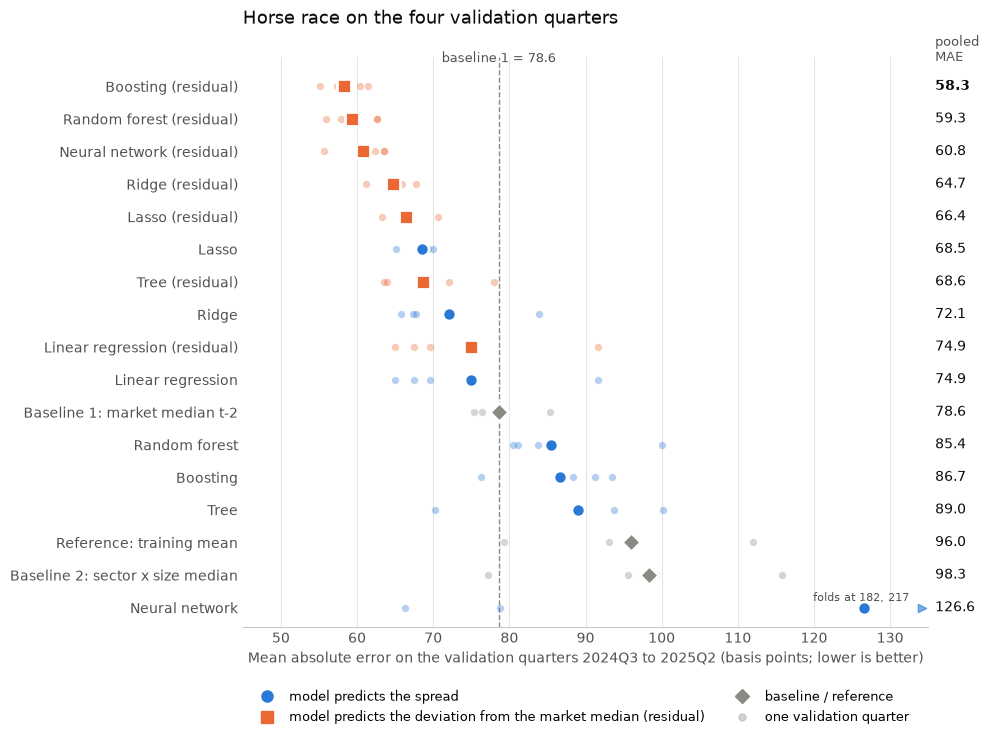

written: data/processed/predictions_validation.csv, 11475 rows, 17 models; output/tables/horse_race_validation.csv, output/tables/tuning_default_vs_tuned.csv, output/figures/horse_race_validation.png


In [14]:
# The race in one picture (as in notebooks 209 and 210). Each small dot is one validation quarter, the large marker
# the pooled MAE (the choice criterion). Colour and marker shape both encode the round, so colour is never needed alone.
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
X_MAX = 135                                   # fold MAEs beyond this are drawn at the edge and labelled
style = lambda n: ((GREY, "D") if ("aseline" in n or "Reference" in n) else ((ORANGE, "s") if "residual" in n else (BLUE, "o")))
order = race.index[::-1]                       # best model on top
fig, ax = plt.subplots(figsize=(10, 7.5))
for i, name in enumerate(order):
    colour, marker = style(name)
    folds_mae = by_fold.loc[name].to_numpy()
    inside = folds_mae <= X_MAX
    ax.scatter(folds_mae[inside], [i] * inside.sum(), s=28, color=colour, alpha=0.35, linewidths=0, zorder=2)
    if (~inside).any():                        # off-scale folds: one arrow at the edge, values listed beside it
        ax.scatter([X_MAX - 0.8], [i], marker=">", s=36, color=colour, alpha=0.6, zorder=2)
        ax.text(X_MAX - 2.5, i + 0.3, "folds at " + ", ".join(f"{v:.0f}" for v in sorted(folds_mae[~inside])),
                ha="right", va="center", fontsize=8, color=MUTED)
    mae = race.loc[name, "mae_bps"]
    ax.scatter([min(mae, X_MAX - 0.8)], [i], s=90, color=colour, marker=marker, edgecolors="white", linewidths=2, zorder=3)
    ax.text(1.01, i, f"{mae:.1f}", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=10,
            color=INK, fontweight="bold" if i == len(order) - 1 else "normal")
b1 = race.loc["Baseline 1: market median t-2", "mae_bps"]
ax.axvline(b1, color=GREY, ls="--", lw=1, zorder=1)
ax.text(b1, len(order) - 0.35, f"baseline 1 = {b1:.1f}", ha="center", va="bottom", fontsize=9, color=MUTED)
ax.text(1.01, len(order) - 0.35, "pooled\nMAE", transform=ax.get_yaxis_transform(), ha="left", va="bottom",
        fontsize=9, color=MUTED)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=10, color=INK)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xlim(45, X_MAX)
ax.set_xlabel("Mean absolute error on the validation quarters 2024Q3 to 2025Q2 (basis points; lower is better)",
              fontsize=10, color=MUTED)
ax.grid(axis="x", color="#e5e4e0", lw=0.8, zorder=0)
ax.tick_params(colors=MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c8c3")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=BLUE, markersize=8, label="model predicts the spread"),
           Line2D([], [], marker="s", ls="", color=ORANGE, markersize=8,
                  label="model predicts the deviation from the market median (residual)"),
           Line2D([], [], marker="D", ls="", color=GREY, markersize=7, label="baseline / reference"),
           Line2D([], [], marker="o", ls="", color=GREY, alpha=0.35, markersize=5, label="one validation quarter")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.09), ncol=2, frameon=False, fontsize=9)
ax.set_title("Horse race on the four validation quarters", loc="left", fontsize=13, color=INK, pad=24)
fig.tight_layout()
fig.savefig(FIG / "horse_race_validation.png", dpi=200, bbox_inches="tight")
plt.show()

val.to_csv(PROC / "predictions_validation.csv", index=False)
print("written: data/processed/predictions_validation.csv,", len(val), "rows,", val["model"].nunique(), "models;",
      "output/tables/horse_race_validation.csv, output/tables/tuning_default_vs_tuned.csv,",
      "output/figures/horse_race_validation.png")